In [41]:
import numpy as np
import pickle
import matplotlib.pyplot as plt
from random import shuffle

In [42]:
r_scape = pickle.load(open("data/eval_rscape.pickle", "rb"))
datasets = list(map(str.strip, open("3d.txt", "r")))

In [43]:
def extract_hyperparameters(dict):
    keys = [k[1:] for k in dict.keys()]
    return set(keys)

In [55]:
def best_hyper(dict, train_set):
    best_score = -1
    best_hyperparameters = None
    for key in dict.keys():
        score = 0
        for dataset in train_set:
            if key[0] != dataset:
                continue
            score += dict[key][1]
        
        if score > best_score:
            best_score = score
            best_hyperparameters = key[1:]
    return best_hyperparameters

In [80]:
best_hyper(r_scape, datasets)

('GTp',)

In [58]:
def cross_validation(data, splits = 5):
    local_datasets = list(datasets)
    # shuffle the datasets
    shuffle(local_datasets)

    #split in splits folds
    numpy = np.array(local_datasets)
    folds = np.array_split(numpy, splits)

    results = []
    for i in range(splits):
        test = set(folds[i])
        train = set(numpy) - test

        best_hyperparameters = best_hyper(r_scape, train)
        print(f"Best hyperparameters for fold {i}: {best_hyperparameters}")
        for dataset in test:
            results.append(r_scape[(dataset, *best_hyperparameters)][1])
        
    return np.mean(results) * 100

In [77]:
cross_validation(r_scape)

Best hyperparameters for fold 0: ('GTp',)
Best hyperparameters for fold 1: ('GTp',)
Best hyperparameters for fold 2: ('GTp',)
Best hyperparameters for fold 3: ('CHIa',)
Best hyperparameters for fold 4: ('GTp',)


np.float64(67.16332589310663)

In [78]:
results = [cross_validation(r_scape) for _ in range(1000)]

Best hyperparameters for fold 0: ('GTp',)
Best hyperparameters for fold 1: ('CHIa',)
Best hyperparameters for fold 2: ('GTp',)
Best hyperparameters for fold 3: ('GTp',)
Best hyperparameters for fold 4: ('GTp',)
Best hyperparameters for fold 0: ('GTp',)
Best hyperparameters for fold 1: ('GTp',)
Best hyperparameters for fold 2: ('GTp',)
Best hyperparameters for fold 3: ('GTp',)
Best hyperparameters for fold 4: ('CHIp',)
Best hyperparameters for fold 0: ('GTp',)
Best hyperparameters for fold 1: ('GTp',)
Best hyperparameters for fold 2: ('GTp',)
Best hyperparameters for fold 3: ('GTp',)
Best hyperparameters for fold 4: ('CHIa',)
Best hyperparameters for fold 0: ('GTp',)
Best hyperparameters for fold 1: ('GTp',)
Best hyperparameters for fold 2: ('GTp',)
Best hyperparameters for fold 3: ('GTp',)
Best hyperparameters for fold 4: ('CHIa',)
Best hyperparameters for fold 0: ('GTp',)
Best hyperparameters for fold 1: ('GTp',)
Best hyperparameters for fold 2: ('GTp',)
Best hyperparameters for fold 

(array([ 2.,  0.,  2.,  0.,  0.,  0.,  0.,  0.,  1.,  5.,  2.,  1.,  5.,
         5.,  3.,  4.,  2.,  2.,  8.,  4., 14., 11.,  5.,  6.,  8.,  6.,
        12.,  9.,  9., 13., 14.,  9., 11., 14.,  9., 12.,  9., 19., 11.,
        20., 14., 16., 14., 19., 25., 18., 28., 25., 14., 25., 21., 19.,
        20., 33., 18., 20., 27., 19., 26., 22., 22., 31., 21., 18., 18.,
        18., 15., 14., 14., 17., 16.,  8.,  9.,  7.,  8., 10.,  3.,  6.,
         3.,  3.,  5.,  0.,  3.,  1.,  3.,  1.,  1.,  1.,  0.,  1.,  1.,
         0.,  0.,  0.,  0.,  0.,  0.,  2.,  1., 29.]),
 array([65.35052561, 65.37574529, 65.40096497, 65.42618466, 65.45140434,
        65.47662402, 65.50184371, 65.52706339, 65.55228308, 65.57750276,
        65.60272244, 65.62794213, 65.65316181, 65.67838149, 65.70360118,
        65.72882086, 65.75404054, 65.77926023, 65.80447991, 65.82969959,
        65.85491928, 65.88013896, 65.90535864, 65.93057833, 65.95579801,
        65.98101769, 66.00623738, 66.03145706, 66.05667675, 66.081896

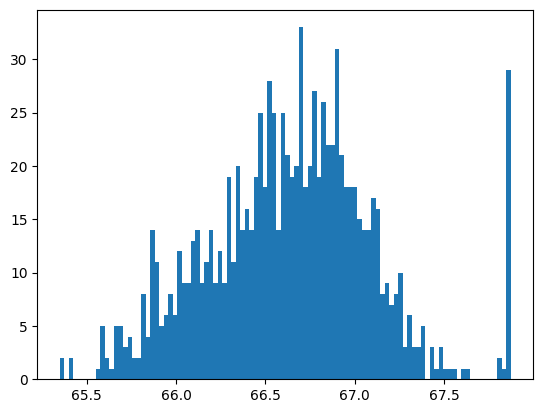

In [79]:
plt.hist(results, bins=100)

In [83]:
np.mean([r_scape[(dataset, "GTp")][1] for dataset in datasets]) * 100

np.float64(67.8724939570725)